# 05 - Association rules: which services are linked together? (Question 2)

**Question:** which external platforms (Twitter, blogs, Flickr, …) do FriendFeed users adopt together?

**Representation:** one transaction (basket) per user = the set of external services the user linked (binary user × service table).
**Goal of this notebook**:
1. Justify the **minimum support** threshold (with absolute counts and a sensitivity analysis).
2. Compare **Apriori** with **FP-Growth**.
3. Summarise the frequent itemsets with **closed** and **maximal** itemsets.
4. Generate rules, rank them by **lift**, and check their **stability** on two random halves of the data.

In [1]:
from pathlib import Path
import time
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

ROOT = Path.cwd().parent
OUT, FIG = ROOT / "data", ROOT / "figures"
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9, "axes.titlesize": 11})

con = duckdb.connect()
pairs = con.sql(f"""
    SELECT s.user_id, s.service_id
    FROM '{(OUT / 'services.parquet').as_posix()}' AS s
    JOIN '{(OUT / 'users.parquet').as_posix()}'    AS u ON s.user_id = u.user_id
    WHERE u.type = 'user'
""").df()

basket_all = pd.crosstab(pairs["user_id"], pairs["service_id"]).astype(bool)
size = basket_all.sum(axis=1)
basket = basket_all[size >= 2]                     # single-service users cannot form rules
N = len(basket)

print(f"users with >= 1 service: {len(basket_all):,}  | services: {basket_all.shape[1]}")
print(f"users with exactly 1 service: {(size == 1).sum():,} ({(size == 1).mean():.1%}) -> excluded")
print(f"baskets used for mining (N): {N:,}")
print(f"services per basket: median {basket.sum(axis=1).median():.0f}, mean {basket.sum(axis=1).mean():.1f}")

users with >= 1 service: 305,991  | services: 60
users with exactly 1 service: 107,167 (35.0%) -> excluded
baskets used for mining (N): 198,824
services per basket: median 4, mean 5.4


**Findings – the transactions**
- **305,991 individual users** linked at least one of **60** external services (groups excluded). Services are an October snapshot, so the study window does not apply.
- **107,167 users (35%) linked exactly one service.** A one-item basket cannot contain a rule (a rule needs an item on each side), and keeping them would only dilute every support value - decision: excluded.
- **N = 198,824 baskets** are mined; a basket contains a median of 4 services (mean 5.4).
- Each basket is binary (service linked or not): how many accounts of a service a user has does not matter, which is why duplicates were removed.
- *All supports below are relative to these 198,824 multi-service users.*

### Item supports: how common is each service?

services with support >= 5%: 18 of 60


,support,users
service_id,,
twitter,0.850,168988
blog,0.577,114704
flickr,0.428,85161
youtube,0.402,79872
delicious,0.337,67063
facebook,0.287,57050
googletalk,0.243,48344
googlereader,0.242,48151
lastfm,0.220,43838


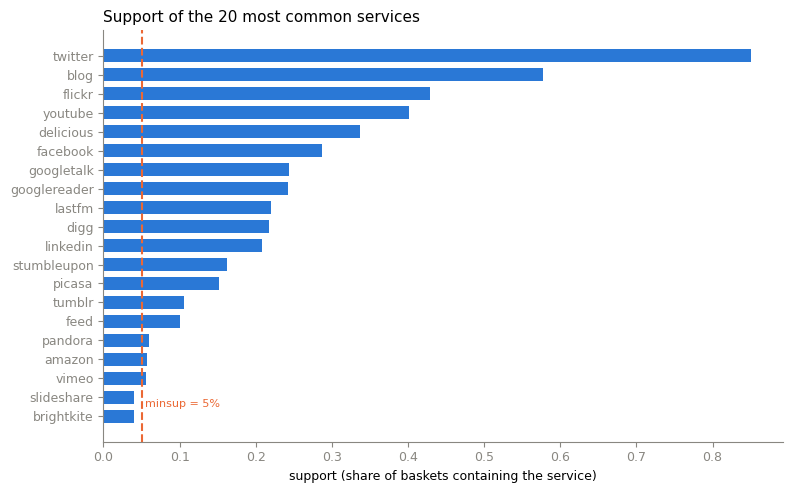

In [2]:
item_support = basket.mean().sort_values(ascending=False)
item_table = pd.DataFrame({"support": item_support.round(3),
                           "users": (item_support * N).round().astype(int)})

top = item_support.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.axvline(0.05, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(0.055, 0.5, "minsup = 5%", color=ORANGE, fontsize=8)
ax.set_xlabel("support (share of baskets containing the service)")
ax.set_title("Support of the 20 most common services", loc="left")
fig.tight_layout(); fig.savefig(FIG / "11_item_support.png", dpi=150)

print("services with support >= 5%:", (item_support >= 0.05).sum(), "of", len(item_support))
item_table.head(15)

**Findings – item supports**
- Support of a single service = share of baskets containing it. **Twitter 85.0%** (168,988 users), blog 57.7%, Flickr 42.8%, YouTube 40.2%, Delicious 33.7%, Facebook 28.7% …
- **Only 18 of the 60 services reach 5% support**; the other 42 are rare (used by < 9,941 of these users).
- Twitter is linked by almost everyone - any rule predicting Twitter will have high confidence regardless of the left side.

### Choosing minsup: sensitivity analysis

,minsup,min users,frequent services,frequent itemsets,"rules (conf>=0.5, lift>1)",seconds
0,0.20,39764,11,26,24,0.1
1,0.10,19882,15,92,139,0.1
2,0.07,13917,15,196,386,0.2
3,0.05,9941,18,348,721,0.4
4,0.03,5964,24,754,1631,0.7
5,0.02,3976,32,1283,2813,1.5


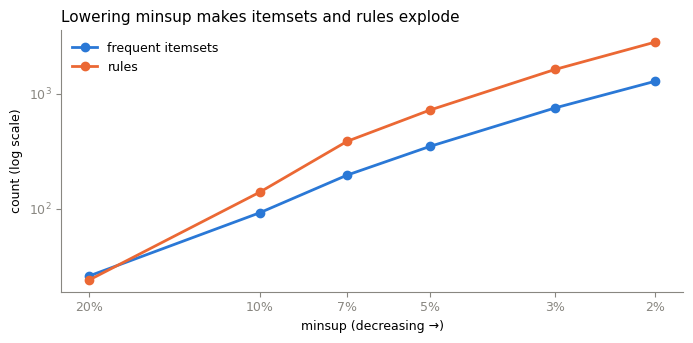

In [3]:
rows = []
for ms in [0.20, 0.10, 0.07, 0.05, 0.03, 0.02]:
    t = time.time()
    f = apriori(basket, min_support=ms, use_colnames=True, max_len=4)
    secs = time.time() - t
    r = association_rules(f, metric="confidence", min_threshold=0.5)
    r = r[r["lift"] > 1]
    rows.append((ms, int(ms * N), (item_support >= ms).sum(), len(f), len(r), round(secs, 1)))
sens = pd.DataFrame(rows, columns=["minsup", "min users", "frequent services",
                                   "frequent itemsets", "rules (conf>=0.5, lift>1)", "seconds"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sens["minsup"], sens["frequent itemsets"], marker="o", color=BLUE, linewidth=2, label="frequent itemsets")
ax.plot(sens["minsup"], sens["rules (conf>=0.5, lift>1)"], marker="o", color=ORANGE, linewidth=2, label="rules")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xticks(sens["minsup"]); ax.set_xticklabels([f"{m:.0%}" for m in sens["minsup"]]); ax.minorticks_off()
ax.set_xlabel("minsup (decreasing →)"); ax.set_ylabel("count (log scale)"); ax.legend(frameon=False)
ax.set_title("Lowering minsup makes itemsets and rules explode", loc="left")
fig.tight_layout(); fig.savefig(FIG / "12_minsup_sensitivity.png", dpi=150)
sens

**Findings – sensitivity of the results to minsup**

| minsup | min. users | frequent services | frequent itemsets | rules |
|---|---|---|---|---|
| 20% | 39,764 | 11 | 26 | 24 |
| 10% | 19,882 | 15 | 92 | 139 |
| 7% | 13,917 | 15 | 196 | 386 |
| **5%** | **9,941** | **18** | **348** | **721** |
| 3% | 5,964 | 24 | 754 | 1,631 |
| 2% | 3,976 | 32 | 1,283 | 2,813 |

**Choice: minsup = 5%**, because
- **evidence:** every frequent itemset and therefore every rule; is supported by at least **9,941 users**, far beyond chance;
- **coverage:** 18 services can take part, including the bookmarking services (Digg, StumbleUpon) that a higher threshold would exclude;
- **manageability:** halving minsup roughly doubles the itemsets and rules each time (exponential growth of the search space), mostly adding variations of the same patterns.
- **Limitation (rare-item problem):** services with support below 5% (42 of 60) can never appear in a rule.

### Final itemsets at minsup = 5%: Apriori vs FP-Growth

In [4]:
MINSUP = 0.05

t = time.time(); freq    = apriori(basket,  min_support=MINSUP, use_colnames=True, max_len=4); t_ap = time.time() - t
t = time.time(); freq_fp = fpgrowth(basket, min_support=MINSUP, use_colnames=True, max_len=4); t_fp = time.time() - t

same = set(map(frozenset, freq["itemsets"])) == set(map(frozenset, freq_fp["itemsets"]))
print(f"Apriori:   {len(freq)} itemsets in {t_ap:.2f} s")
print(f"FP-Growth: {len(freq_fp)} itemsets in {t_fp:.2f} s")
print("same frequent itemsets:", same)
freq["length"] = freq["itemsets"].apply(len)
freq.groupby("length").size().rename("frequent itemsets")

Apriori:   348 itemsets in 0.41 s
FP-Growth: 348 itemsets in 1.81 s
same frequent itemsets: True


length
1     18
2     84
3    155
4     91
Name: frequent itemsets, dtype: int64

**Findings – Apriori vs FP-Growth**
- Both algorithms find exactly the **same 348 frequent itemsets** (they are exact algorithms; they differ only in how they search).
  - *Apriori* generates candidate itemsets level by level and prunes with the anti-monotone property (a superset of an infrequent itemset is infrequent).
  - *FP-Growth* compresses the transactions into an FP-tree and mines it recursively without generating candidates.
- Runtime here: Apriori 0.41 s, FP-Growth 1.81 s. With only 60 items and short baskets, candidate generation is cheap, so Apriori is not slower in this implementation; FP-Growth's advantage shows with many items / long transactions / low minsup.
- Itemset sizes: 18 single services, 84 pairs, 155 triples, 91 quadruples (`max_len = 4`).

### Closed and maximal frequent itemsets

In [5]:
sup = dict(zip(freq["itemsets"], freq["support"]))

def has_superset(itemset, same_support):
    for other, s in sup.items():
        if len(other) == len(itemset) + 1 and itemset < other:
            if not same_support or np.isclose(s, sup[itemset]):
                return True
    return False

freq["closed"]  = [not has_superset(i, same_support=True)  for i in freq["itemsets"]]
freq["maximal"] = [not has_superset(i, same_support=False) for i in freq["itemsets"]]
print(f"frequent: {len(freq)} | closed: {freq['closed'].sum()} | maximal: {freq['maximal'].sum()}")

maximal = freq[freq["maximal"]].sort_values("support", ascending=False).copy()
maximal["users"] = (maximal["support"] * N).round().astype(int)
maximal[["itemsets", "support", "users", "length"]].head(12)

frequent: 348 | closed: 348 | maximal: 139


,itemsets,support,users,length
294,"(blog, flickr, youtube, twitter)",0.137232,27285,4
265,"(flickr, blog, delicious, twitter)",0.125473,24947,4
320,"(flickr, youtube, delicious, twitter)",0.115223,22909,4
275,"(blog, youtube, delicious, twitter)",0.108765,21625,4
266,"(blog, youtube, delicious, flickr)",0.091563,18205,4
341,"(flickr, youtube, lastfm, twitter)",0.088465,17589,4
288,"(flickr, blog, lastfm, twitter)",0.086815,17261,4
315,"(flickr, lastfm, delicious, twitter)",0.083969,16695,4
284,"(flickr, googlereader, blog, twitter)",0.083873,16676,4
330,"(flickr, digg, youtube, twitter)",0.082344,16372,4


**Findings – closed and maximal itemsets**
- **Closed itemset:** no immediate superset has the *same* support (keeps all support information).
- **Maximal itemset:** no superset is frequent at all (the "border" of the frequent itemsets; most compact, but loses the supports of subsets).
- Result: **348 frequent - 348 closed - 139 maximal.**
  - Every frequent itemset is closed: with ~200,000 baskets, adding a service practically always removes at least a few users, so supports never tie exactly - closed itemsets give no compression here.
  - **Maximal itemsets reduce the output by 60%** (348 - 139) and summarise which combinations reach 5% support.
- The most common maximal combinations: {YouTube, blog, Twitter, Flickr} (13.7%, 27,285 users), {Delicious, blog, Twitter, Flickr} (12.5%), {Delicious, YouTube, Twitter, Flickr} (11.5%) - a **general content-sharing bundle** (blogging + photos + videos + bookmarks + Twitter).

### Rules: confidence >= 0.5, ranked by lift

In [6]:
rules = association_rules(freq.drop(columns=["closed", "maximal", "length"]),
                          metric="confidence", min_threshold=0.5)
rules = rules[rules["lift"] > 1].sort_values("lift", ascending=False)
rules["users"] = (rules["support"] * N).round().astype(int)
print(f"{len(rules)} rules with confidence >= 0.5 and lift > 1")

show = ["antecedents", "consequents", "antecedent support", "consequent support",
        "support", "users", "confidence", "lift"]
rules[show].head(12).round(3)

721 rules with confidence >= 0.5 and lift > 1


,antecedents,consequents,antecedent support,consequent support,support,users,confidence,lift
551,"(digg, delicious, twitter)",(stumbleupon),0.118,0.162,0.063,12452,0.532,3.286
163,"(digg, delicious)",(stumbleupon),0.132,0.162,0.069,13810,0.527,3.258
554,"(stumbleupon, delicious)","(digg, twitter)",0.101,0.191,0.063,12452,0.622,3.255
552,"(stumbleupon, delicious, twitter)",(digg),0.089,0.217,0.063,12452,0.701,3.228
164,"(stumbleupon, delicious)",(digg),0.101,0.217,0.069,13810,0.690,3.177
654,"(flickr, stumbleupon)","(digg, twitter)",0.086,0.191,0.050,9987,0.585,3.061
668,"(youtube, stumbleupon)","(digg, twitter)",0.097,0.191,0.056,11161,0.580,3.037
652,"(flickr, stumbleupon, twitter)",(digg),0.077,0.217,0.050,9987,0.651,3.001
666,"(youtube, stumbleupon, twitter)",(digg),0.086,0.217,0.056,11161,0.650,2.996
224,"(flickr, stumbleupon)",(digg),0.086,0.217,0.055,10883,0.637,2.936


**Findings - rules ranked by lift** (confidence ≥ 0.5, lift > 1 → **721 rules**)

| Rule | support(X) | support(Y) | support | users | confidence | lift |
|---|---|---|---|---|---|---|
| {digg, delicious} → {stumbleupon} | 0.132 | 0.162 | 0.069 | 13,810 | 0.53 | **3.26** |
| {delicious, stumbleupon} → {digg} | 0.101 | 0.217 | 0.069 | 13,810 | 0.69 | 3.18 |
| {stumbleupon, flickr} → {digg} | 0.086 | 0.217 | 0.055 | 10,883 | 0.64 | 2.94 |

**Reading the top rule:** 13,810 users (6.9%) link all three services; of the users who link Digg and Delicious (13.2%), 53% also link StumbleUpon; StumbleUpon's baseline is only 16.2%, so the rule raises the chance **3.26-fold**.

**Interpretation:** the strongest associations form a **social-bookmarking / link-sharing bundle** - Digg, Delicious and StumbleUpon. Users active in one link-sharing community are much more likely to be active in the others.
Many top rules are the same itemset split differently (e.g. {digg, delicious, stumbleupon}).

### Which pairs of services go together? (2-item rules, lift matrix)

highest lift pairs:
service_id    service_id 
digg          stumbleupon    2.66
delicious     stumbleupon    1.85
              digg           1.80
googlereader  lastfm         1.69
digg          linkedin       1.68
linkedin      stumbleupon    1.66
dtype: float64
lowest lift pairs:
service_id  service_id  
blog        facebook        0.93
            googletalk      0.98
twitter     googlereader    1.00
            blog            1.00
dtype: float64


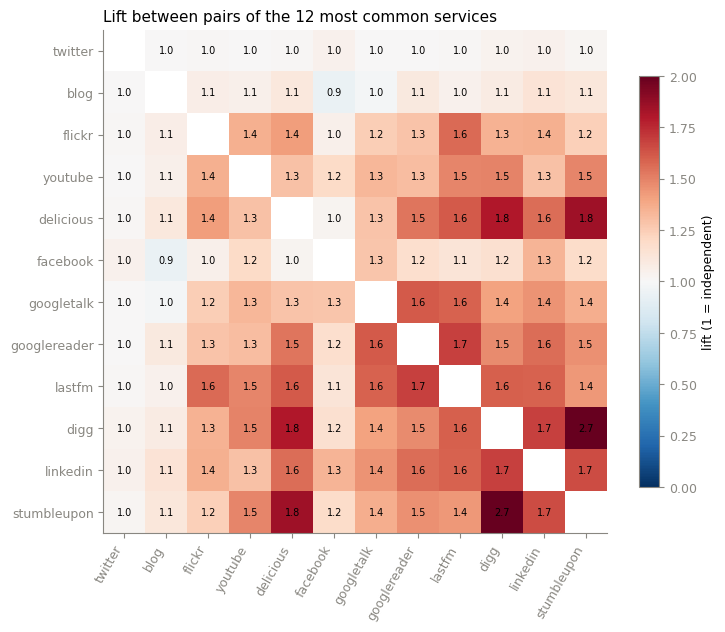

In [7]:
top_items = item_support.head(12).index
pair_lift = pd.DataFrame(index=top_items, columns=top_items, dtype=float)
for a in top_items:
    for b in top_items:
        if a != b:
            both = (basket[a] & basket[b]).mean()
            pair_lift.loc[a, b] = both / (item_support[a] * item_support[b])

fig, ax = plt.subplots(figsize=(7.5, 6.3))
im = ax.imshow(pair_lift.astype(float), cmap="RdBu_r", vmin=0, vmax=2)
ax.set_xticks(range(len(top_items))); ax.set_xticklabels(top_items, rotation=60, ha="right")
ax.set_yticks(range(len(top_items))); ax.set_yticklabels(top_items)
for i in range(len(top_items)):
    for j in range(len(top_items)):
        if i != j:
            ax.text(j, i, f"{pair_lift.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="lift (1 = independent)")
ax.set_title("Lift between pairs of the 12 most common services", loc="left")
fig.tight_layout(); fig.savefig(FIG / "13_pair_lift.png", dpi=150)

pl = pair_lift.where(np.triu(np.ones(pair_lift.shape), 1).astype(bool)).stack().astype(float)
print("highest lift pairs:"); print(pl.sort_values(ascending=False).head(6).round(2))
print("lowest lift pairs:");  print(pl.sort_values().head(4).round(2))

**Findings – pairwise lift between the 12 most common services**
- Strongest pairs: **Digg–StumbleUpon 2.66**, Delicious–StumbleUpon 1.85, Delicious–Digg 1.80, Google Reader–Last.fm 1.69, Digg–LinkedIn 1.68.
- **Lift ≈ 1** for Twitter with Google Reader or blog (1.00): independent - Twitter is everywhere, so knowing it says nothing.
- Lift < 1 for blog–Facebook (0.93): slightly *negatively* associated - users linking a blog are a bit less likely than average to link Facebook.
- The pairwise matrix confirms the rule results with a simpler, two-item view.

### The Twitter trap: high confidence, lift ≈ 1

In [8]:
all_rules = association_rules(freq.drop(columns=["closed", "maximal", "length"]),
                              metric="confidence", min_threshold=0.0)
to_twitter = all_rules[all_rules["consequents"] == frozenset({"twitter"})]
print(f"support(twitter) = {item_support['twitter']:.3f}")
to_twitter.sort_values("confidence", ascending=False)[["antecedents", "consequents", "support",
                                                      "confidence", "lift"]].head(5).round(3)

support(twitter) = 0.850


,antecedents,consequents,support,confidence,lift
1826,"(flickr, facebook, delicious)",(twitter),0.060,0.927,1.091
1392,"(digg, blog, linkedin)",(twitter),0.050,0.925,1.089
672,"(digg, facebook)",(twitter),0.067,0.925,1.088
1784,"(digg, linkedin, delicious)",(twitter),0.050,0.925,1.088
1840,"(youtube, facebook, delicious)",(twitter),0.058,0.924,1.088


**Findings - the Twitter trap (confidence vs lift)**
- support(Twitter) = **0.85**: 85% of multi-service users link Twitter.
- Rules into Twitter reach **confidence 0.93**, e.g. {digg, facebook} - {twitter}, but **lift only 1.09** - the left side barely changes the chance of Twitter (85% - 92.5%).
- **Confidence = P(Y | X) ignores how common Y is**; when Y is very frequent almost any rule into Y looks strong. **Lift = confidence / support(Y)** compares with that baseline (> 1 positive association, ≈ 1 independence, < 1 negative).
- **Decision:** rules are filtered (lift > 1) and ranked by lift, not by confidence.

### Stability: do the rules hold on two random halves?

In [9]:
rng = np.random.default_rng(42)
half = rng.random(N) < 0.5
A, B = basket[half], basket[~half]

def mine(b):
    f = apriori(b, min_support=MINSUP, use_colnames=True, max_len=4)
    r = association_rules(f, metric="confidence", min_threshold=0.5)
    r = r[r["lift"] > 1]
    return r.set_index(r["antecedents"].astype(str) + " -> " + r["consequents"].astype(str))

rA, rB = mine(A), mine(B)
common = rA.index.intersection(rB.index)
print(f"rules in half A: {len(rA)} | half B: {len(rB)} | in both: {len(common)} "
      f"({len(common) / len(rA.index.union(rB.index)):.1%} of all)")
print("correlation of lift between halves:", round(np.corrcoef(rA.loc[common, "lift"], rB.loc[common, "lift"])[0, 1], 3))
print("max absolute lift difference:", round((rA.loc[common, "lift"] - rB.loc[common, "lift"]).abs().max(), 3))
top10 = rules.head(10)
key = top10["antecedents"].astype(str) + " -> " + top10["consequents"].astype(str)
print("top-10 rules found in both halves:", key.isin(common).sum(), "of 10")

rules in half A: 722 | half B: 720 | in both: 706 (95.9% of all)
correlation of lift between halves: 0.999
max absolute lift difference: 0.077
top-10 rules found in both halves: 10 of 10


**Findings – stability on two random halves**
- The baskets are split randomly into two halves (~99,400 each) and rules are mined separately with the same settings.
- **722 vs 720 rules; 706 found in both halves (95.9%)**; the rules found in only one half lie at the thresholds (support ≈ 5% or confidence ≈ 0.5).
- **Lift values agree almost perfectly** between the halves (correlation **0.999**, largest difference 0.08).
- **All top-10 rules appear in both halves.**
 The rules are not artefacts of particular users; they are supported by sufficient, reproducible evidence (checklist: *results supported by sufficient evidence*).

**Answer to Question 2:** users link services in recognisable bundles  most strongly a **social-bookmarking bundle (Digg, Delicious, StumbleUpon; lift ≈ 3)** and a broader **content-sharing bundle** (blog, Flickr, YouTube, Delicious with Twitter). Twitter itself is so universal that it carries no association information (lift ≈ 1).